In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
import keras
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from keras.layers import Dense
from keras.models import Sequential

In [2]:
# Generate two interleaving half circles (moons dataset)
X, y = make_moons(n_samples=500, noise=0.1, random_state=42)

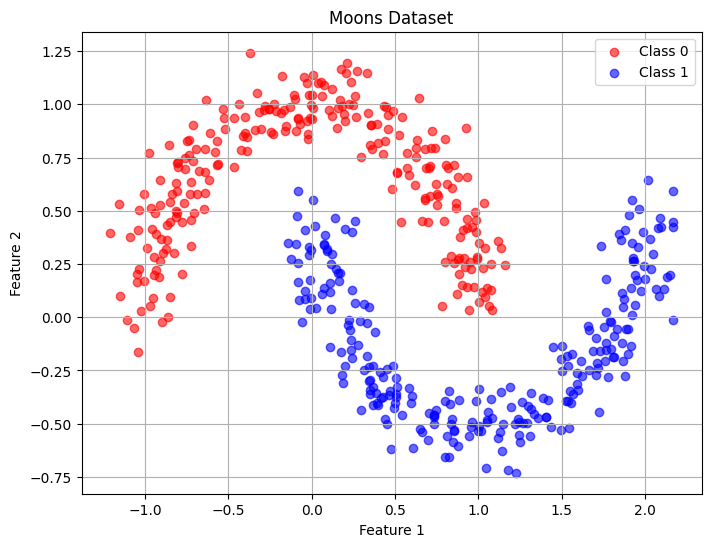

In [3]:
# Plot the dataset to visualize it
plt.figure(figsize=(8, 6))
plt.scatter(X[y == 0, 0], X[y == 0, 1], color='red', label='Class 0', alpha=0.6)
plt.scatter(X[y == 1, 0], X[y == 1, 1], color='blue', label='Class 1', alpha=0.6)
plt.title("Moons Dataset")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.grid(True)
plt.show()

In [4]:
model = Sequential()

model.add(Dense(10,activation='sigmoid',input_dim=2))
model.add(Dense(10,activation='sigmoid'))
model.add(Dense(10,activation='sigmoid'))
model.add(Dense(10,activation='sigmoid'))
model.add(Dense(10,activation='sigmoid'))
model.add(Dense(10,activation='sigmoid'))
model.add(Dense(10,activation='sigmoid'))
model.add(Dense(10,activation='sigmoid'))
model.add(Dense(10,activation='sigmoid'))
model.add(Dense(10,activation='sigmoid'))
model.add(Dense(10,activation='sigmoid'))
model.add(Dense(1, activation='sigmoid'))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [5]:
model.compile(loss='binary_crossentropy',optimizer='adam',metrics=['accuracy'])

In [6]:
old_weights = model.get_weights()[0]

In [7]:
model.get_weights()[0]

array([[-0.3319727 ,  0.59902686,  0.48622578,  0.33237463,  0.6485842 ,
        -0.44371983, -0.18324286,  0.43965822, -0.6875208 , -0.65630484],
       [ 0.53986543,  0.39849418,  0.5755064 ,  0.2652033 , -0.4791065 ,
         0.2733407 ,  0.59121233, -0.44220102, -0.4299265 , -0.2623041 ]],
      dtype=float32)

In [8]:
# Split into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

In [9]:
# note : first check with 1 epoch then 100
model.fit(X_train, y_train, epochs = 100)

Epoch 1/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.5175 - loss: 0.6933 
Epoch 2/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.5175 - loss: 0.6926 
Epoch 3/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.5175 - loss: 0.6927 
Epoch 4/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.5175 - loss: 0.6927 
Epoch 5/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.5175 - loss: 0.6926 
Epoch 6/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.5175 - loss: 0.6926 
Epoch 7/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.5175 - loss: 0.6926 
Epoch 8/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.5175 - loss: 0.6926 
Epoch 9/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5175 - loss: 0.6927 
Epoch 10/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.5175 - loss: 0.6933 
Epoch 11/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5175 - loss: 0.6926 
Epoch 12/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 

In [10]:
new_weights = model.get_weights()[0]

In [11]:
model.optimizer.get_config()["learning_rate"]

0.0010000000474974513

In [12]:
gradient = (old_weights - new_weights)/ 0.001
percent_change = abs(100*(old_weights - new_weights)/ old_weights)

In [13]:
gradient

array([[  12.949555 ,  -21.025656 ,  -53.99054  ,   46.799957 ,
         -29.164373 ,   -5.047917 ,   33.219917 , -100.86697  ,
          -5.0956006,   46.69195  ],
       [ -10.909259 ,   21.763712 ,   47.684845 ,  -38.436413 ,
          32.55409  ,    4.468113 ,  -24.875341 ,   90.68352  ,
           2.4242997,  -46.94566  ]], dtype=float32)

In [14]:
percent_change

array([[ 3.9007895,  3.509969 , 11.104007 , 14.080483 ,  4.496621 ,
         1.1376362, 18.128902 , 22.942133 ,  0.7411559,  7.1143694],
       [ 2.0207367,  5.461488 ,  8.285721 , 14.493188 ,  6.79475  ,
         1.6346315,  4.2075143, 20.507307 ,  0.563887 , 17.897419 ]],
      dtype=float32)

#Here occurs VGP i.e very less(0.0000) rate of change has happend . old and new gradient is very close to each other

to slove the problem apply following task

# 5 way to handle VGP
1. reduce model complexity(reduce hidden layers)

In [15]:
model = Sequential()

model.add(Dense(10,activation='sigmoid',input_dim=2))
model.add(Dense(10,activation='sigmoid'))
model.add(Dense(10,activation='sigmoid'))
model.add(Dense(1, activation='sigmoid'))

In [16]:
model.compile(loss='binary_crossentropy',optimizer='adam',metrics=['accuracy'])

In [17]:
model.get_weights()[0]

array([[ 0.37206966, -0.6120501 ,  0.17086077, -0.30611256, -0.5657149 ,
         0.46732372, -0.28125754, -0.06798035, -0.21750504,  0.15570426],
       [-0.6707072 ,  0.4317518 , -0.59277856,  0.48906344,  0.6706088 ,
         0.5290213 ,  0.27148688, -0.44974497, -0.53056276,  0.4744081 ]],
      dtype=float32)

In [18]:
old_weights = model.get_weights()[0]

In [19]:
model.fit(X_train, y_train, epochs = 100)

Epoch 1/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.5175 - loss: 0.6907
Epoch 2/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5175 - loss: 0.6895 
Epoch 3/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5175 - loss: 0.6884 
Epoch 4/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5175 - loss: 0.6873 
Epoch 5/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5175 - loss: 0.6862 
Epoch 6/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5175 - loss: 0.6851 
Epoch 7/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5175 - loss: 0.6838 
Epoch 8/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5200 - loss: 0.6824 
Epoch 9/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5225 - loss: 0.6808 
Epoch 10/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5275 - loss: 0.6790 
Epoch 11/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5575 - loss: 0.6769 
Epoch 12/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step -

In [20]:
new_weights = model.get_weights()[0]

In [21]:
model.optimizer.get_config()["learning_rate"]

0.0010000000474974513

In [22]:
gradient = (old_weights - new_weights)/ 0.001
percent_change = abs(100*(old_weights - new_weights)/ old_weights)

In [23]:
gradient

array([[-3.4671604e+01,  6.7174429e-01, -2.2145917e+02, -1.6604214e+01,
         8.6385603e+00,  3.6920108e+02,  1.6116177e+02, -4.0530682e+02,
        -3.4129889e+02,  4.1549228e+02],
       [ 1.0427771e+03, -1.1131157e+03,  1.1671407e+03, -8.9117242e+02,
        -1.0434091e+03, -1.0846903e+03, -1.1493411e+03,  1.3086669e+03,
         1.0686588e+03, -1.3004469e+03]], dtype=float32)

In [24]:
percent_change

array([[9.3185787e+00, 1.0975316e-01, 1.2961383e+02, 5.4242187e+00,
        1.5270166e+00, 7.9003281e+01, 5.7300430e+01, 5.9621179e+02,
        1.5691541e+02, 2.6684708e+02],
       [1.5547427e+02, 2.5781381e+02, 1.9689322e+02, 1.8222021e+02,
        1.5559132e+02, 2.0503717e+02, 4.2335052e+02, 2.9097980e+02,
        2.0141988e+02, 2.7411990e+02]], dtype=float32)

In [25]:
old_weights

array([[ 0.37206966, -0.6120501 ,  0.17086077, -0.30611256, -0.5657149 ,
         0.46732372, -0.28125754, -0.06798035, -0.21750504,  0.15570426],
       [-0.6707072 ,  0.4317518 , -0.59277856,  0.48906344,  0.6706088 ,
         0.5290213 ,  0.27148688, -0.44974497, -0.53056276,  0.4744081 ]],
      dtype=float32)

In [26]:
new_weights

array([[ 0.40674126, -0.61272186,  0.39231995, -0.28950834, -0.57435346,
         0.09812263, -0.44241932,  0.3373265 ,  0.12379387, -0.25978804],
       [-1.7134844 ,  1.5448675 , -1.7599194 ,  1.3802359 ,  1.714018  ,
         1.6137117 ,  1.420828  , -1.7584119 , -1.5992216 ,  1.774855  ]],
      dtype=float32)

#2. Using RelU activation funcation
if negative 0
else 1

daawback: dying relu (activation 0 hole deri 0 so no loss happend)
to slove: use leaky relu

In [27]:
model = Sequential()

model.add(Dense(10,activation='relu',input_dim=2))
model.add(Dense(10,activation='relu'))
model.add(Dense(10,activation='relu'))
model.add(Dense(10,activation='relu'))
model.add(Dense(10,activation='relu'))
model.add(Dense(10,activation='relu'))
model.add(Dense(10,activation='relu'))
model.add(Dense(10,activation='relu'))
model.add(Dense(10,activation='relu'))
model.add(Dense(10,activation='relu'))
model.add(Dense(10,activation='relu'))
model.add(Dense(1, activation='sigmoid'))

In [28]:
model.compile(loss='binary_crossentropy',optimizer='adam',metrics=['accuracy'])

In [29]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

In [30]:
model.fit(X_train, y_train, epochs = 100)

Epoch 1/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.5000 - loss: 0.6891
Epoch 2/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.5175 - loss: 0.6773 
Epoch 3/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.6875 - loss: 0.6499 
Epoch 4/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8075 - loss: 0.5912 
Epoch 5/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8475 - loss: 0.5086 
Epoch 6/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8575 - loss: 0.4310 
Epoch 7/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8575 - loss: 0.3633 
Epoch 8/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8700 - loss: 0.2939 
Epoch 9/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8850 - loss: 0.2482 
Epoch 10/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9050 - loss: 0.2246 
Epoch 11/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9025 - loss: 0.2010 
Epoch 12/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step -

In [31]:
new_weights = model.get_weights()[0]

In [32]:
model.optimizer.get_config()["learning_rate"]

0.0010000000474974513

In [33]:
gradient = (old_weights - new_weights)/ 0.001
percent_change = abs(100*(old_weights - new_weights)/ old_weights)

In [34]:
gradient

array([[  281.74435 ,  -310.0262  ,   631.8761  ,   -97.181625,
          110.760025,   984.8406  ,  -826.89386 ,   612.152   ,
         -578.8972  ,   909.5503  ],
       [-1061.9985  ,   -63.057957, -1100.829   ,   704.55524 ,
          805.1784  ,   343.67807 ,    21.54523 ,  -524.98096 ,
          -47.605095,  1062.9045  ]], dtype=float32)

In [35]:
percent_change

array([[ 75.72356  ,  50.653732 , 369.8193   ,  31.747026 ,  19.578772 ,
        210.74055  , 293.99884  , 900.4837   , 266.1535   , 584.1525   ],
       [158.34012  ,  14.605141 , 185.70662  , 144.06215  , 120.06679  ,
         64.96488  ,   7.9360123, 116.72859  ,   8.972567 , 224.04858  ]],
      dtype=float32)

In [36]:
old_weights

array([[ 0.37206966, -0.6120501 ,  0.17086077, -0.30611256, -0.5657149 ,
         0.46732372, -0.28125754, -0.06798035, -0.21750504,  0.15570426],
       [-0.6707072 ,  0.4317518 , -0.59277856,  0.48906344,  0.6706088 ,
         0.5290213 ,  0.27148688, -0.44974497, -0.53056276,  0.4744081 ]],
      dtype=float32)

In [37]:
new_weights

array([[ 0.0903253 , -0.3020239 , -0.4610153 , -0.20893092, -0.6764749 ,
        -0.5175169 ,  0.54563636, -0.6801323 ,  0.36139223, -0.75384605],
       [ 0.3912914 ,  0.49480975,  0.50805044, -0.21549185, -0.13456963,
         0.18534324,  0.24994165,  0.07523599, -0.48295766, -0.58849657]],
      dtype=float32)

3. Proper Weight initilization

      => gloral

      => xavior

4. Batch Normalization
5. Using a Residual Network(building block) use ResNet
